# Metrics and comparison of YOLOv26 models

This notebook creates the YOLOv26 comparison charts from the artifacts stored in `models/`, rather than from manually entered metric values.

- **Global mAP@0.5:** best value in each variant's `results.csv`.
- **mAP@0.5 by class:** a fresh validation of each stored `weights/best.pt` checkpoint against the repository dataset.

Run from any directory inside the project repository; `PROJECT_ROOT` is detected automatically.

## Generate charts from saved results

Run the next cell alone. It reads the YOLOv26 `results.csv` files and the saved per-class validation cache in `models/comparisons/`. It exports PDF and 300 dpi PNG files to `notebooks/generated/figures/`. The figures show the highest recorded global mAP@0.5 and per-class validation mAP@0.5, respectively.


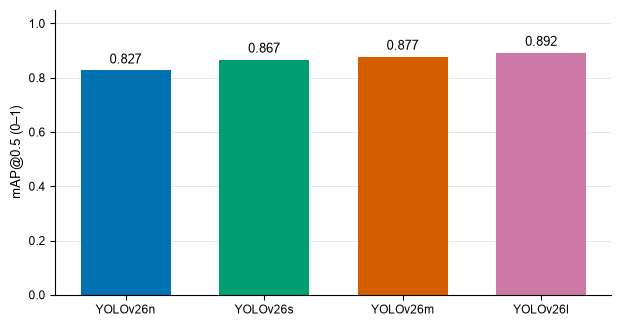

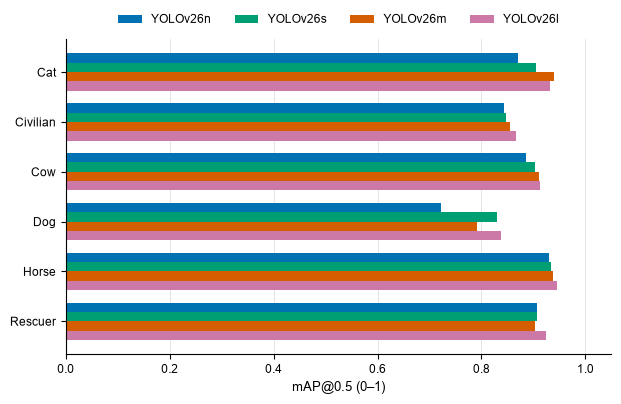

In [1]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
project_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "dataset" / "data.yaml").is_file() and (p / "models").is_dir()), None)
if project_root is None:
    raise FileNotFoundError("Open this notebook from inside the project repository.")
import sys
style_dir = str(project_root / "src")
if style_dir not in sys.path:
    sys.path.insert(0, style_dir)
from evaluation.plotting.comparison_figures import plot_per_class_map50, plot_variant_map50
from evaluation.plotting.style import configure_figures
configure_figures()
models_dir = project_root / "models"
variants = [v for v in ("n", "s", "m", "l")
            if (models_dir / f"yolov26{v}" / "results.csv").is_file()]
if not variants:
    raise FileNotFoundError("No YOLOv26 results.csv files found under models/.")
values = []
for variant in variants:
    with (models_dir / f"yolov26{variant}" / "results.csv").open(newline="") as file:
        rows = list(csv.DictReader(file))
    values.append(max(float(row["metrics/mAP50(B)"]) for row in rows))
fig = plot_variant_map50(variants, values, project_root)
plt.show()

cache_path = models_dir / "comparisons" / "yolov26-per-class-map50.json"
if cache_path.is_file():
    saved = json.loads(cache_path.read_text())
    available = [v for v in variants if v in saved["models"]]
    if available:
        fig = plot_per_class_map50(saved["classes"], available, saved["models"], project_root)
        plt.show()
else:
    print("Per-class numbers are not cached yet. Run the full validation section once.")


## Load recorded training metrics

The global comparison reads the best recorded validation mAP@0.5 from each model artifact.

In [2]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

from pathlib import Path
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "dataset" / "data.yaml").is_file() and (p / "models").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the project repository.")
import yaml
with (PROJECT_ROOT / "dataset" / "data.yaml").open() as file:
    dataset_config = yaml.safe_load(file)
MODELS_DIR = PROJECT_ROOT / "models"
DATA_YAML = PROJECT_ROOT / "dataset" / "data.yaml"
VARIANTS = tuple(v for v in ("n", "s", "m", "l") if (MODELS_DIR / f"yolov26{v}" / "results.csv").is_file())
MODEL_LABELS = [f"YOLOv26{variant}" for variant in VARIANTS]
METRIC_COLUMN = "metrics/mAP50(B)"

def artifact_path(variant, filename):
    path = MODELS_DIR / f"yolov26{variant}" / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing model artifact: {path}")
    return path

def best_map50(variant):
    with artifact_path(variant, "results.csv").open(newline="") as file:
        rows = list(csv.DictReader(file))
    if not rows or METRIC_COLUMN not in rows[0]:
        raise KeyError(f"{METRIC_COLUMN} is missing from YOLOv26{variant} results.csv")
    return max(float(row[METRIC_COLUMN]) for row in rows)

map50 = [best_map50(variant) for variant in VARIANTS]
print(dict(zip(MODEL_LABELS, map50)))

{'YOLOv26n': 0.82672, 'YOLOv26s': 0.86674, 'YOLOv26m': 0.87736, 'YOLOv26l': 0.89192}


## Global mAP@0.5 per variant

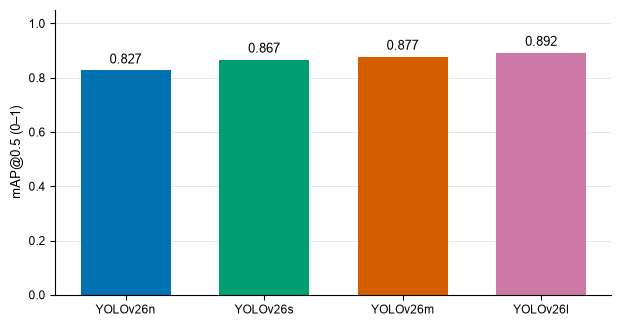

In [3]:
import sys
style_dir = str(PROJECT_ROOT / "src")
if style_dir not in sys.path:
    sys.path.insert(0, style_dir)
from evaluation.plotting.comparison_figures import plot_variant_map50
from evaluation.plotting.style import configure_figures
configure_figures()
fig = plot_variant_map50(VARIANTS, map50, PROJECT_ROOT)
plt.show()


## mAP@0.5 per class

This cell re-evaluates the stored best checkpoint for each variant. It may take several minutes, but keeps the per-class chart synchronized with the actual weights and dataset.

In [ ]:
classes = dataset_config["names"]
if isinstance(classes, dict):
    classes = [classes[i] for i in sorted(classes)]
per_class_map50 = {}

for variant in VARIANTS:
    checkpoint = artifact_path(variant, "weights/best.pt")
    metrics = YOLO(str(checkpoint)).val(data=str(DATA_YAML), imgsz=640, verbose=False)
    all_ap = np.asarray(metrics.box.all_ap)
    scores = np.full(len(classes), np.nan)
    scores[np.asarray(metrics.box.ap_class_index, dtype=int)] = all_ap[:, 0]  # IoU = 0.5
    per_class_map50[variant] = scores


import sys
style_dir = str(PROJECT_ROOT / "src")
if style_dir not in sys.path:
    sys.path.insert(0, style_dir)
from evaluation.plotting.comparison_figures import plot_per_class_map50
from evaluation.plotting.style import configure_figures
configure_figures()
fig = plot_per_class_map50(classes, VARIANTS, per_class_map50, PROJECT_ROOT)
plt.show()

# Cache the exact per-class values for the standalone quick chart.
import json
from importlib.metadata import version
cache_path = MODELS_DIR / "comparisons" / "yolov26-per-class-map50.json"
cache_path.parent.mkdir(parents=True, exist_ok=True)
cache_path.write_text(json.dumps({
    "source": "validation of models/yolov26*/weights/best.pt on dataset/data.yaml",
    "imgsz": 640,
    "split": "valid",
    "dataset_images": sum(path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
                          for path in (PROJECT_ROOT / "dataset" / "valid" / "images").iterdir()),
    "ultralytics_version": version("ultralytics"),
    "classes": classes,
    "models": {variant: [None if np.isnan(score) else float(score) for score in scores]
               for variant, scores in per_class_map50.items()},
}, indent=2) + "\n")
print(f"Saved per-class metrics: {cache_path}")
